首先明确其四个最重要的核心：

+ KV Cache 应用于推理阶段<br>
KV Cache 主要用于模型的推理阶段。在这个阶段，键（K）和值（V）的值保持不变，因此可以通过缓存这些值来避免重复计算。<br>
+ KV Cache 只存在于解码器中<br>
KV Cache 技术通常应用于解码器部分。这是因为解码器在生成输出时需要进行多次矩阵运算，而 KV Cache 可以显著优化这一过程。<br>
+ 加速 Q@K@V 的矩阵相乘<br>
KV Cache 的主要目的是加速 Q@K@V 的两次矩阵相乘操作。通过把 K 和 V 的值缓存显存中，模型可以减少计算量，从而提高推理速度。<br>
+ KV Cache 会增加显存占用<br>
尽管 KV Cache 可以加速推理过程，但它也会增加显存的占用。这是因为需要额外的存储空间来保存缓存的 K 和 V 值。

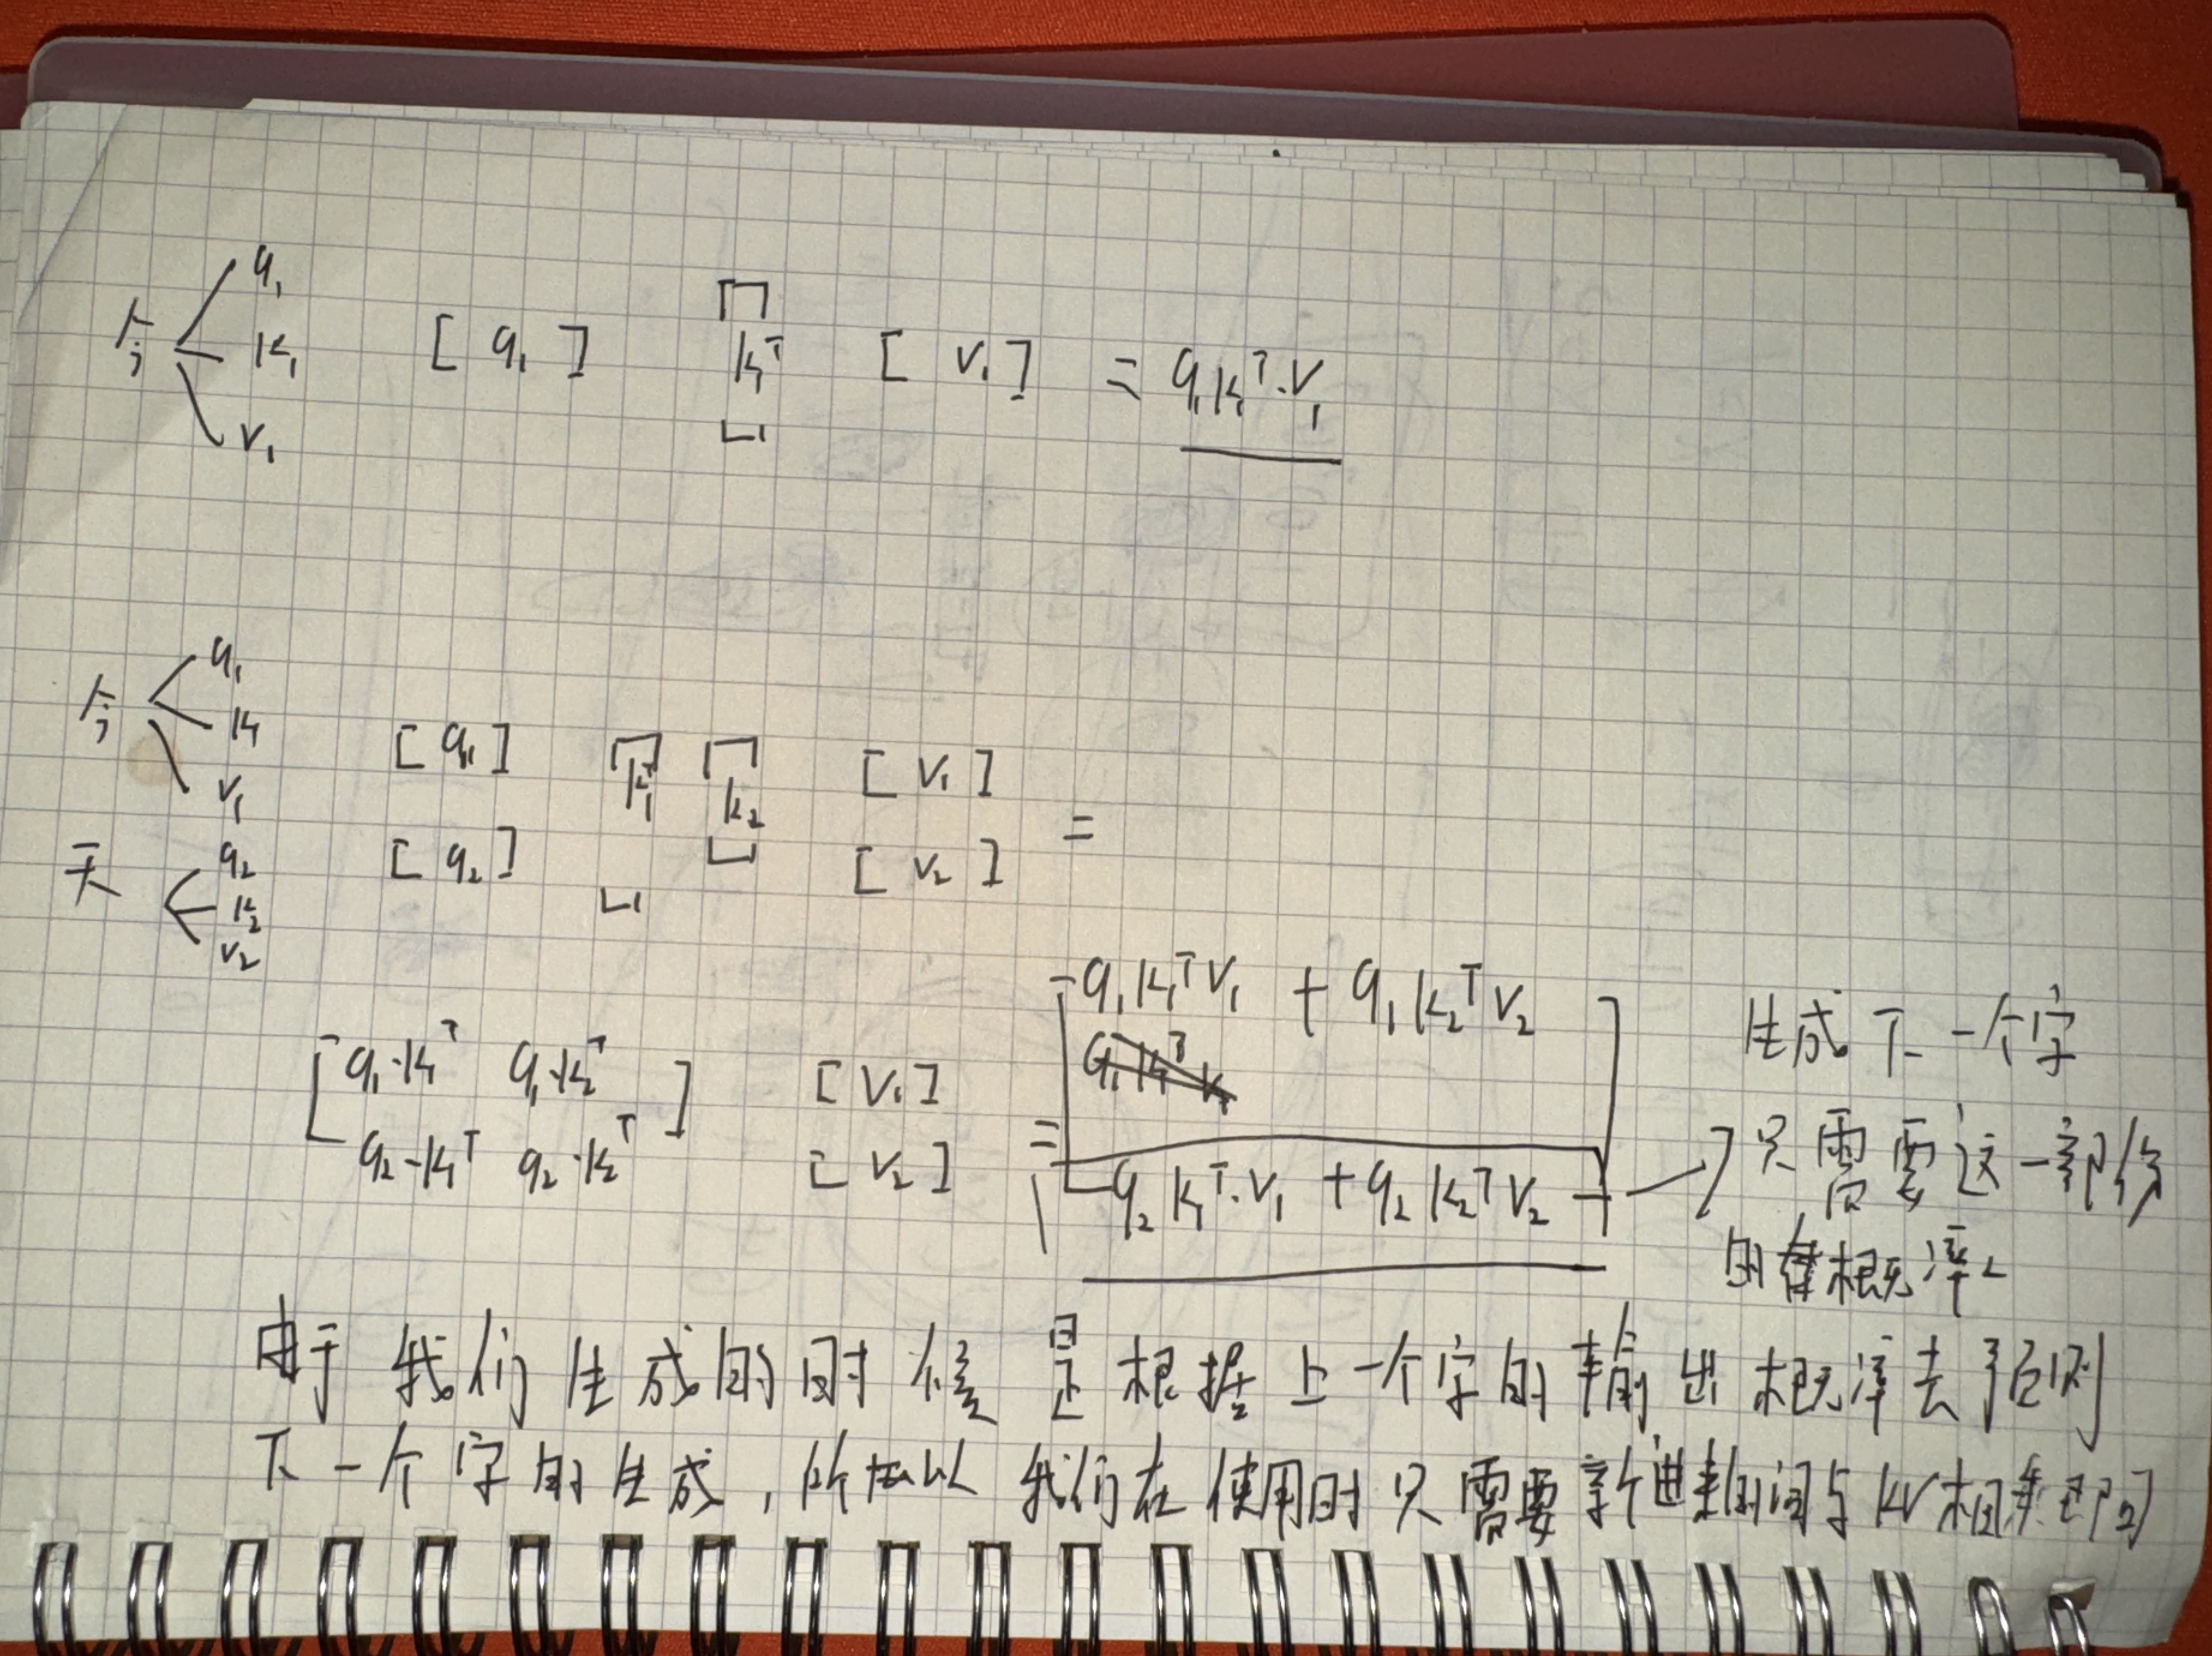

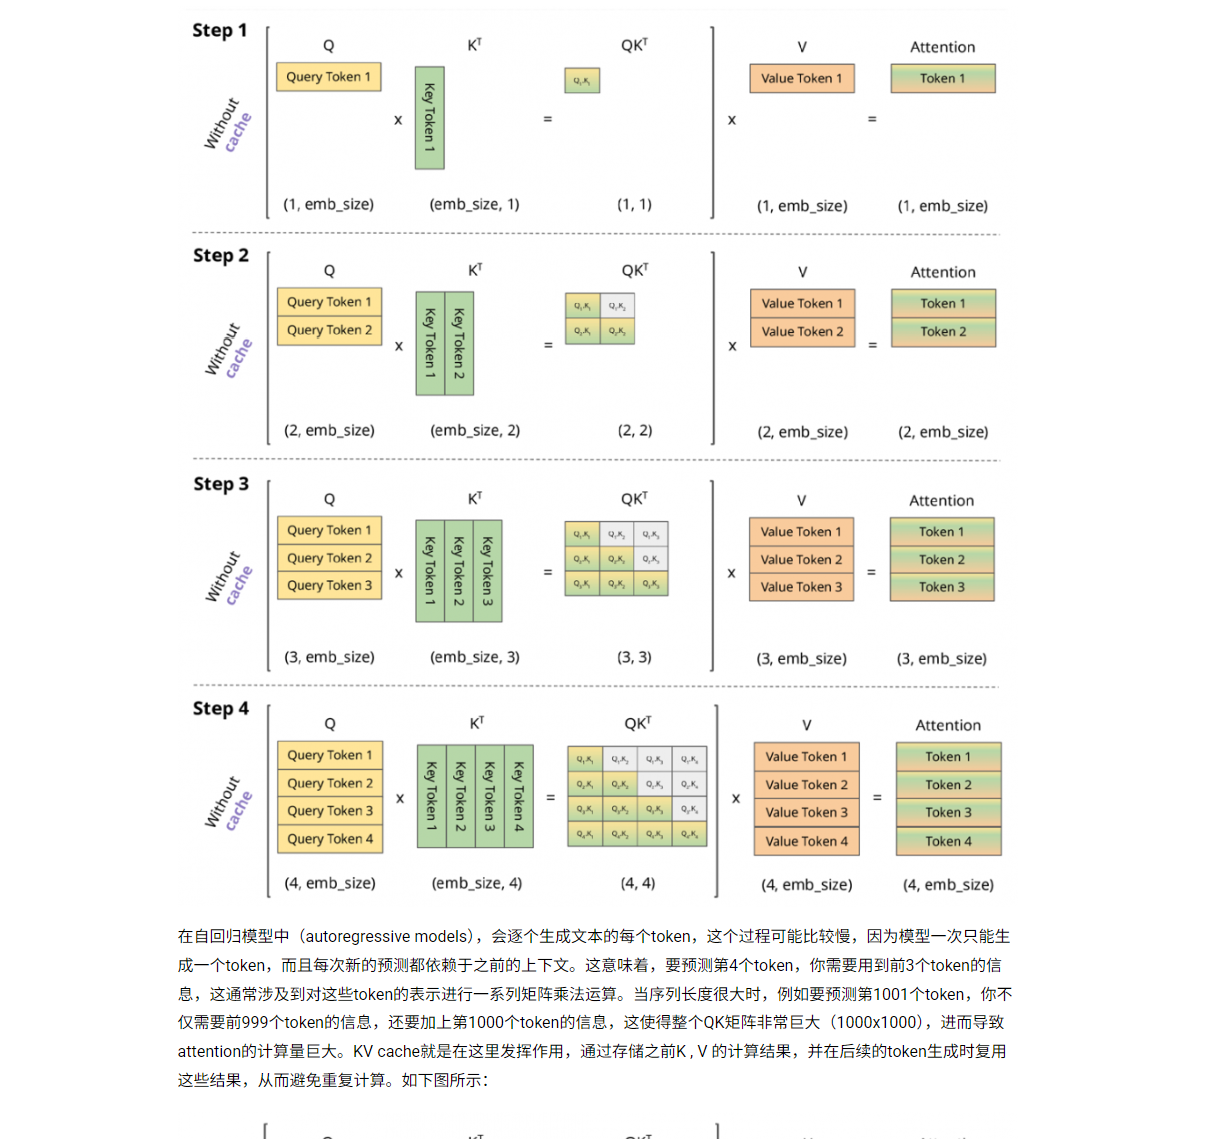

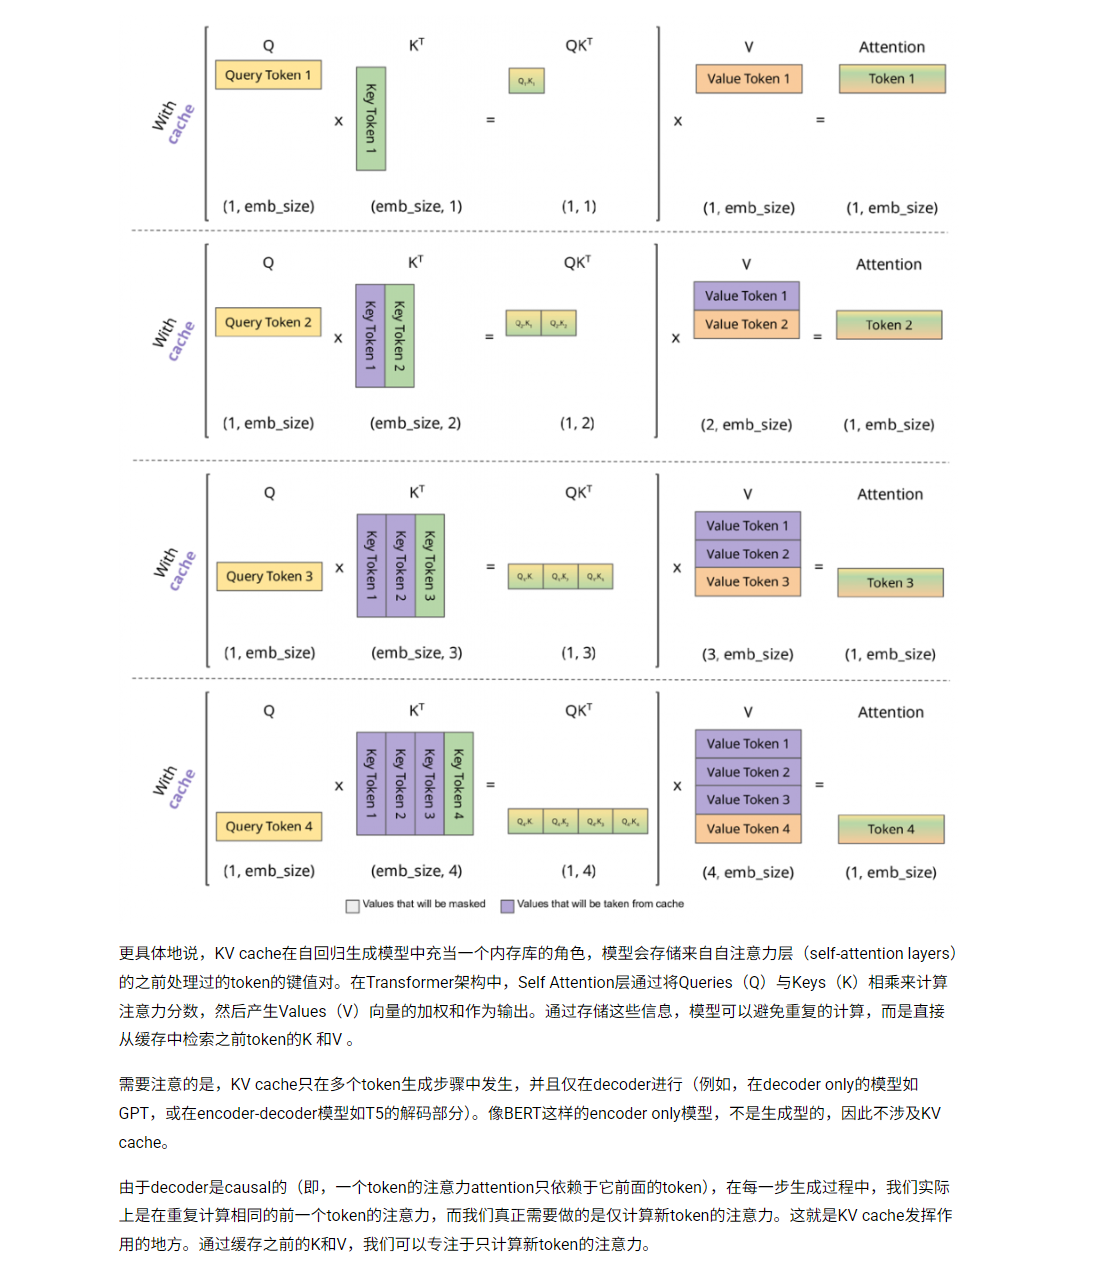

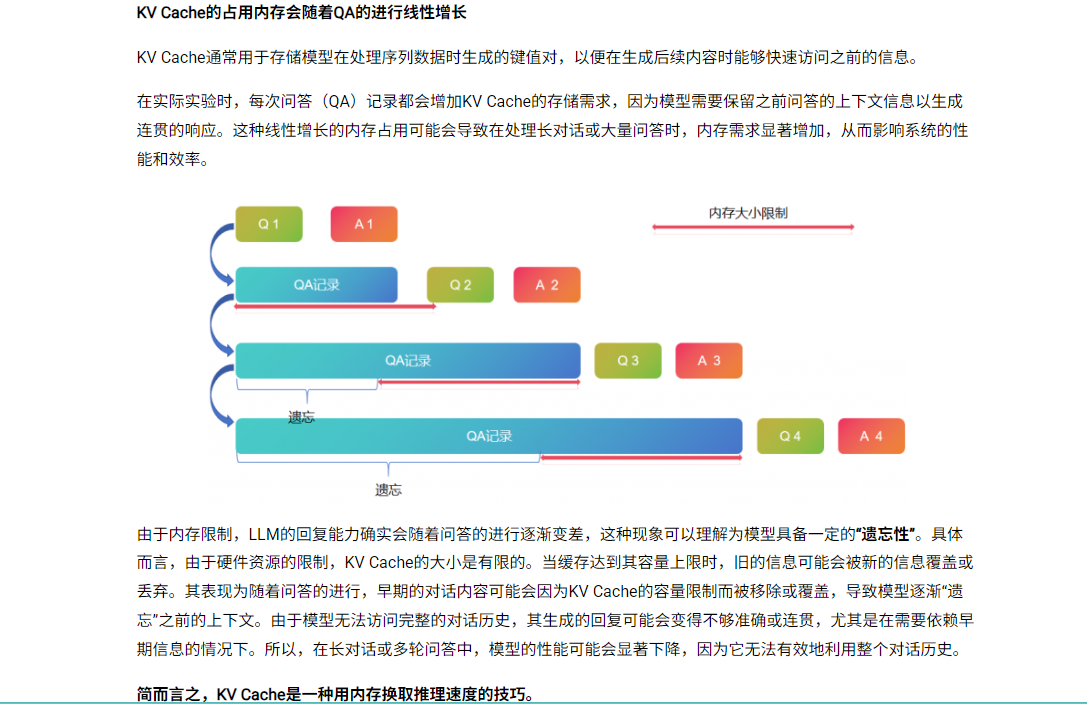

KV Cache核心思想：
+ 1.缓存历史token的key和value向量
+ 2.只计算当前token的query,key和value向量
+ 3.复用缓存的key和value向量

1.transformer推理的大部分时间在逐个 token 生成阶段<br>
2.把历史计算的 KV 保存起来，每次只计算当前的 KV<br>
3.kv cache通过存储之前K , V的计算结果，并在后续的token⽣成时复⽤这些结果，从⽽避免重复计算。<br>

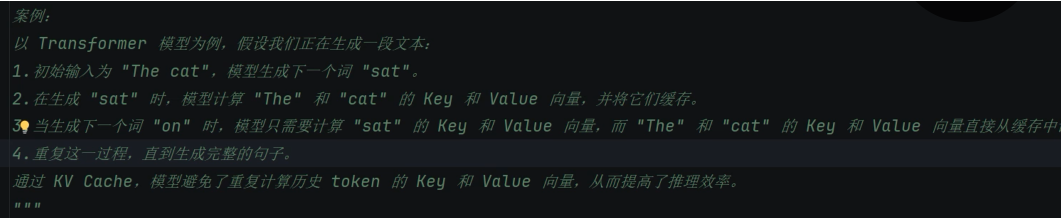

KV Cache的局限性:
+ 1.内存占用增加
+ 2.实现复杂度高

KV Cache的优势:
+ 1.减少计算量
+ 2.提高推理速度
+ 3.适用长序列的生成

为什么只存储K和V，而不存储Q？

由于Q是当前时间步的输入，每次生成新token时都会重新计算Q，不需要缓存。
而K和V可以复用之前时间步的计算结果，通过缓存K和V，可以避免在每个时间步重新计算它们，从而提升效率。

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super(MultiHeadAttention, self).__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        assert self.head_dim * num_heads == embed_dim, "embed_dim must be divisible by num_heads"

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, query, key, value, kvcache=None):
        batch_size, seq_len, embed_dim = query.size()

        # Linear projections
        Q = self.q_proj(query)  # [batch_size, seq_len, embed_dim]
        K = self.k_proj(key)    # [batch_size, seq_len, embed_dim]
        V = self.v_proj(value)  # [batch_size, seq_len, embed_dim]

        # Reshape to multi-head
        Q = Q.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)  # [batch_size, num_heads, seq_len, head_dim]
        K = K.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        V = V.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)

        # If KVCache is provided, concatenate with cached keys and values
        if kvcache is not None:
            K_cache, V_cache = kvcache
            K = torch.cat([K_cache, K], dim=2)  # Concatenate along sequence length
            V = torch.cat([V_cache, V], dim=2)

        # Scaled dot-product attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.head_dim ** 0.5)  # [batch_size, num_heads, seq_len, seq_len + cache_len]
        attn_weights = F.softmax(scores, dim=-1)
        attn_output = torch.matmul(attn_weights, V)  # [batch_size, num_heads, seq_len, head_dim]

        # Reshape back to original size
        attn_output = attn_output.transpose(1, 2).contiguous().view(batch_size, seq_len, embed_dim)  # [batch_size, seq_len, embed_dim]

        # Final linear projection
        output = self.out_proj(attn_output)
        return output, (K, V)  # Return output and updated KVCache

class DecoderLayer(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super(DecoderLayer, self).__init__()
        self.self_attn = MultiHeadAttention(embed_dim, num_heads)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim)
        )

    def forward(self, x, kvcache=None):
        # Self-attention
        attn_output, new_kvcache = self.self_attn(x, x, x, kvcache)
        x = x + self.norm1(attn_output)  # Add & Norm

        # Feed-forward network
        ffn_output = self.ffn(x)
        x = x + self.norm2(ffn_output)  # Add & Norm

        return x, new_kvcache

class Decoder(nn.Module):
    def __init__(self, embed_dim, num_heads, num_layers, vocab_size):
        super(Decoder, self).__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim)  # 嵌入层
        self.layers = nn.ModuleList([DecoderLayer(embed_dim, num_heads) for _ in range(num_layers)])
        self.vocab_proj = nn.Linear(embed_dim, vocab_size)  # 将输出映射到词表

    def forward(self, x, kvcache=None):
        # 将输入token转换为嵌入向量
        x = self.embed(x)  # [batch_size, seq_len] -> [batch_size, seq_len, embed_dim]

        new_kvcache = []
        for i, layer in enumerate(self.layers):
            x, kvcache_i = layer(x, kvcache[i] if kvcache else None)
            new_kvcache.append(kvcache_i)
        logits = self.vocab_proj(x)  # 映射到词表
        return logits, new_kvcache

# 示例使用
if __name__ == "__main__":
    # 参数设置
    embed_dim = 4096
    num_heads = 32
    num_layers = 6
    vocab_size = 32000  # 假设词表大小为 32000
    seq_len = 4
    batch_size = 1

    # 创建Decoder
    decoder = Decoder(embed_dim, num_heads, num_layers, vocab_size)

    # 模拟输入：你是谁？
    input_tokens = torch.randint(0, vocab_size, (batch_size, seq_len))  # [batch_size, seq_len]

    # 初始KVCache为空
    kvcache = None

    # 生成10个token
    generated_tokens = []
    for _ in range(10):
        # 前向传播，返回KVcache值
        logits, kvcache = decoder(input_tokens, kvcache)

        # 选择最后一个token的logits
        next_token_logits = logits[:, -1, :]  # [batch_size, vocab_size]

        # 使用贪心算法选择下一个token
        input_tokens = torch.argmax(next_token_logits, dim=-1).unsqueeze(1)  # [batch_size, 1]

        # 记录生成的token
        generated_tokens.append(input_tokens.item())

    # 打印生成的token
    print("Generated tokens:", generated_tokens)

Generated tokens: [17216, 19064, 17216, 19064, 17216, 19064, 5276, 29625, 5276, 29625]


https://mp.weixin.qq.com/s/-njtbgqnccPo36brYzhgzw

https://mp.weixin.qq.com/s/Ks3R2j_mXu2KHDkTvW6tEw

https://mp.weixin.qq.com/s?__biz=MzU5NjY0NzA4NA==&mid=2247486262&idx=1&sn=4ca215beaeb6f2d38c0c3a3045024bc9&chksm=fe5ec6f5c9294fe3149bfc0d65c0941e503c51358956db98155b5fc894057300a9a225964698&cur_album_id=3777748487262208000&scene=189#wechat_redirect

https://mp.weixin.qq.com/s/ZOP-5G9wp3R0_oau83kThA

https://mp.weixin.qq.com/s/lJaLJQpM8qqYJ8hCJCIH8A

https://mp.weixin.qq.com/s/Zhf2GKTnWeIqpleG6C75bg